In [6]:
import urllib.request

# URL for OpenCV's standard "Messi" test image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/messi5.jpg"
image_path = "images/input_sample.jpg"

# Download and replace the old image
urllib.request.urlretrieve(url, image_path)
print(f"New image downloaded and saved to '{image_path}'!")

New image downloaded and saved to 'images/input_sample.jpg'!


Q3 -> Height: 342, Width: 548, Channels: 3
Q4 -> Total Pixels: 187416
Q5 -> Data Type: uint8


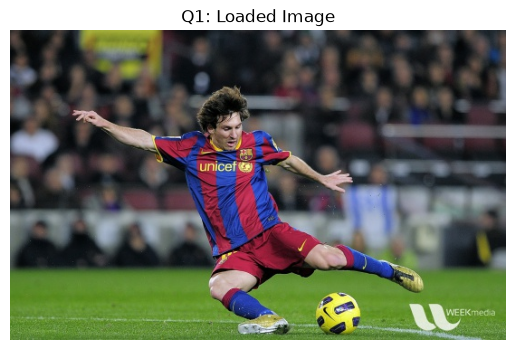

In [7]:
import cv2
import matplotlib.pyplot as plt

# Q1 & Q2: Read image and check if loaded successfully
image_path = 'images/input_sample.jpg'
img_bgr = cv2.imread(image_path)

if img_bgr is None:
    print(f"Error: Could not load image at '{image_path}'. Make sure the file exists.")
else:
    # Q3: Print height, width, and channels
    height, width, channels = img_bgr.shape
    print(f"Q3 -> Height: {height}, Width: {width}, Channels: {channels}")

    # Q4: Total number of pixels (width * height)
    total_pixels = height * width
    print(f"Q4 -> Total Pixels: {total_pixels}")

    # Q5: Print data type
    print(f"Q5 -> Data Type: {img_bgr.dtype}")

    # Q1: Convert BGR to RGB and display
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    plt.imshow(img_rgb)
    plt.title("Q1: Loaded Image")
    plt.axis('off')
    plt.show()

Q6 -> Image saved successfully to: images/saved_sample.jpg
Q10 -> Original size: 548x342, New size: 274x171


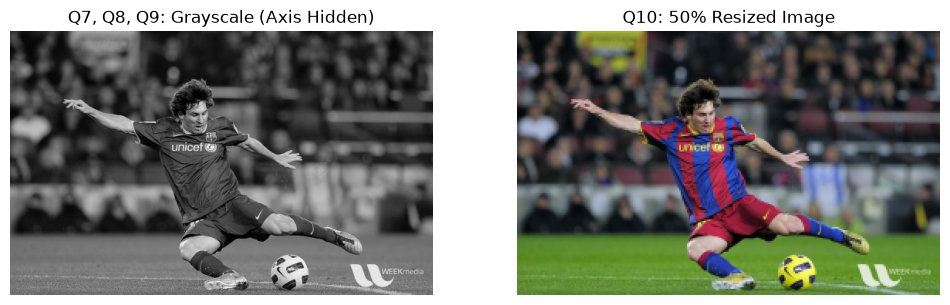

In [8]:
# Q6: Read an image and save it with a different filename
output_path = 'images/saved_sample.jpg'
cv2.imwrite(output_path, img_bgr)
print(f"Q6 -> Image saved successfully to: {output_path}")

# Q7: Read an image directly in grayscale mode
img_gray_direct = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Q8: Convert a color image to grayscale using cv2.cvtColor()
img_gray_converted = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Q10: Resize an image to 50% of its original width and height
# Note: cv2.resize expects dimensions as (width, height)
new_width = int(width * 0.5)
new_height = int(height * 0.5)
img_resized = cv2.resize(img_bgr, (new_width, new_height))
print(f"Q10 -> Original size: {width}x{height}, New size: {new_width}x{new_height}")

# Q9: Display an image using Matplotlib and hide the axis
# Displaying both the grayscale and resized images to visually confirm the outputs
plt.figure(figsize=(12, 5))

# Subplot 1: Direct Grayscale (Q7, Q8, & Q9)
plt.subplot(1, 2, 1)
plt.imshow(img_gray_direct, cmap='gray')
plt.title("Q7, Q8, Q9: Grayscale (Axis Hidden)")
plt.axis('off') # This line specifically satisfies Q9

# Subplot 2: Resized Color Image (Q10)
plt.subplot(1, 2, 2)
img_resized_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
plt.imshow(img_resized_rgb)
plt.title("Q10: 50% Resized Image")
plt.axis('off')

plt.show()

Q11 -> Pixel at (x=100, y=150): [69 69 87]
Q12 -> Modified pixel image saved to 'images/modified_pixel.jpg'
Q13 -> B: 69, G: 69, R: 87
Q16 -> Min intensity: 0, Max intensity: 251
Q17 -> Mean intensity: 83.32
Q18 -> Standard Deviation: 46.39


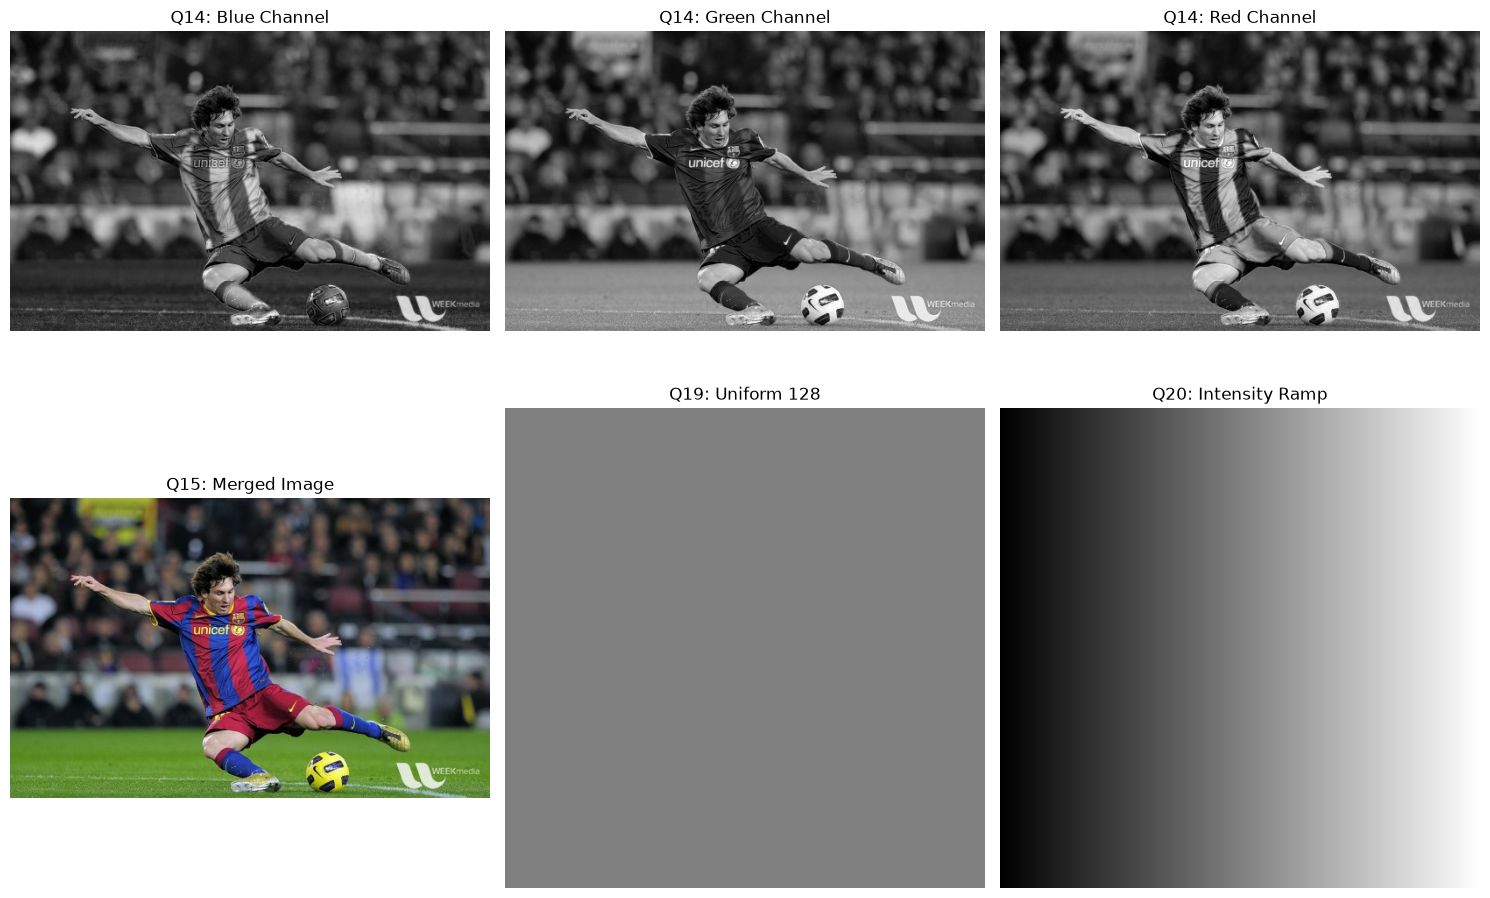

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Reloading base images for this cell's context
img_bgr = cv2.imread('images/input_sample.jpg')
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Q11: Access pixel at user-provided coordinate
x, y = 100, 150 # Hardcoded for smooth notebook execution
pixel_value = img_bgr[y, x] # OpenCV indexes via (row, col) -> (y, x)
print(f"Q11 -> Pixel at (x={x}, y={y}): {pixel_value}")

# Q12: Modify intensity of selected pixel and save
img_bgr_modified = img_bgr.copy()
img_bgr_modified[y, x] = [0, 0, 255] # Changing pixel to Red
cv2.imwrite('images/modified_pixel.jpg', img_bgr_modified)
print("Q12 -> Modified pixel image saved to 'images/modified_pixel.jpg'")

# Q13: Print B, G, R values of the selected pixel
b_val, g_val, r_val = img_bgr[y, x]
print(f"Q13 -> B: {b_val}, G: {g_val}, R: {r_val}")

# Q14 & Q15: Split into channels and Merge them back
b, g, r = cv2.split(img_bgr)
img_merged = cv2.merge((b, g, r))

# Q16: Min and Max intensity values of grayscale image
print(f"Q16 -> Min intensity: {img_gray.min()}, Max intensity: {img_gray.max()}")

# Q17 & Q18: Mean and Standard Deviation using NumPy
print(f"Q17 -> Mean intensity: {np.mean(img_gray):.2f}")
print(f"Q18 -> Standard Deviation: {np.std(img_gray):.2f}")

# Q19: Create 256x256 grayscale image (all pixels = 128)
img_128 = np.full((256, 256), 128, dtype=np.uint8)

# Q20: Create grayscale intensity ramp (0 to 255)
img_ramp = np.tile(np.arange(256, dtype=np.uint8), (256, 1))

# Displaying Q14, Q15, Q19, and Q20 outputs
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(b, cmap='gray'); plt.title("Q14: Blue Channel"); plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(g, cmap='gray'); plt.title("Q14: Green Channel"); plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(r, cmap='gray'); plt.title("Q14: Red Channel"); plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(cv2.cvtColor(img_merged, cv2.COLOR_BGR2RGB)); plt.title("Q15: Merged Image"); plt.axis('off')

# vmin and vmax force Matplotlib to treat 128 as gray, rather than auto-scaling it to white
plt.subplot(2, 3, 5)
plt.imshow(img_128, cmap='gray', vmin=0, vmax=255); plt.title("Q19: Uniform 128"); plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(img_ramp, cmap='gray'); plt.title("Q20: Intensity Ramp"); plt.axis('off')

plt.tight_layout()
plt.show()

Q23 -> Original resolution: 548x342
Q23 -> Downsampled resolution: 274x171
Q25 -> Rotated image saved to 'images/rotated_90.jpg'


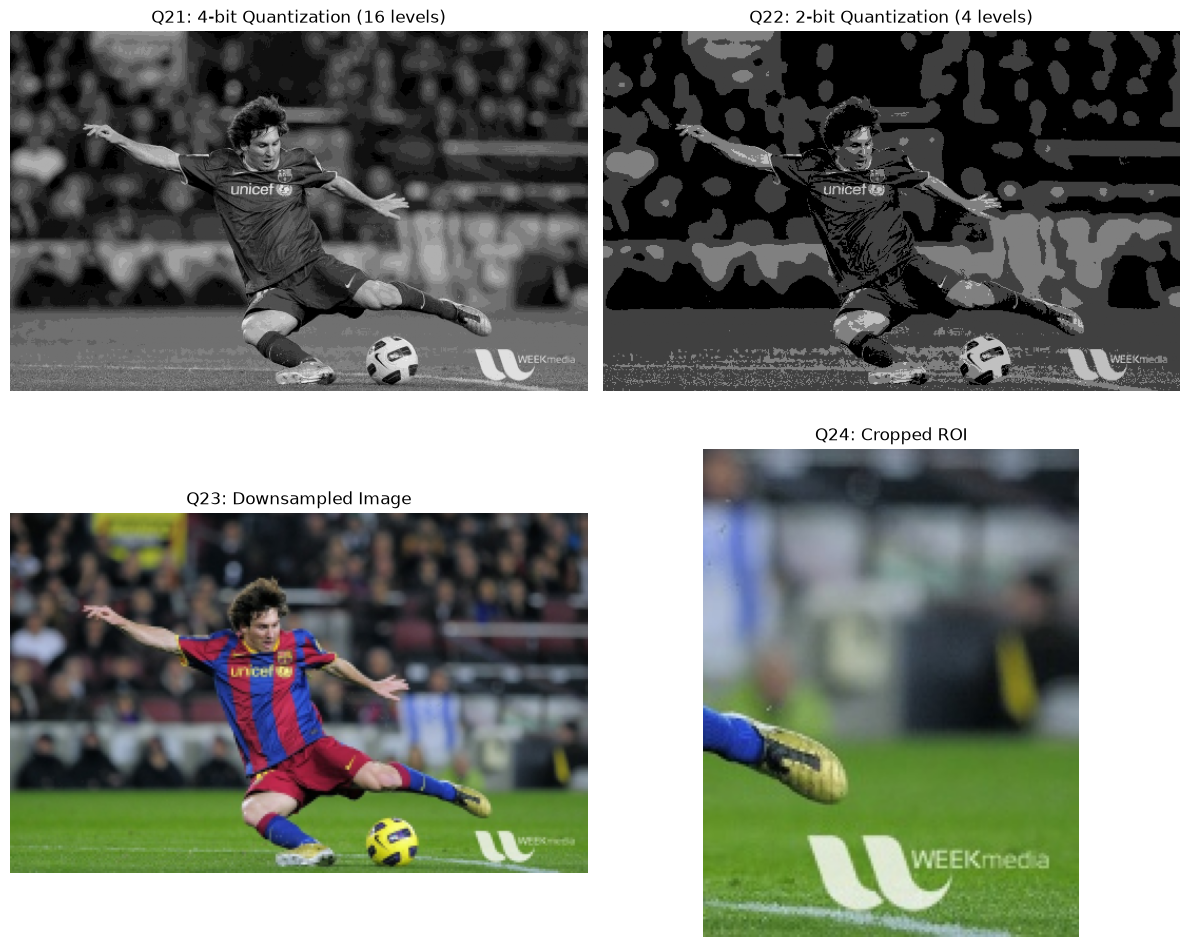

In [10]:
import cv2
import matplotlib.pyplot as plt

# Reloading base images for final section
img_bgr = cv2.imread('images/input_sample.jpg')
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
height, width = img_gray.shape

# Q21: Convert 8-bit grayscale to 4-bit (16 levels)
# Integer division by 16 reduces the 256 levels down to 16, then we multiply back by 16 to make it visible
img_4bit = (img_gray // 16) * 16

# Q22: Convert 8-bit to 2-bit (4 levels)
img_2bit = (img_gray // 64) * 64

# Q23: Downsample by a factor of 2
new_w, new_h = width // 2, height // 2
img_downsampled = cv2.resize(img_bgr, (new_w, new_h))
print(f"Q23 -> Original resolution: {width}x{height}")
print(f"Q23 -> Downsampled resolution: {new_w}x{new_h}")

# Q24: Crop a rectangular Region of Interest (ROI)
# Slicing using array coordinates: [y_start:y_end, x_start:x_end]
roi = img_bgr[150:450, 400:800] 

# Q25: Rotate image by 90 degrees and save
img_rotated = cv2.rotate(img_bgr, cv2.ROTATE_90_CLOCKWISE)
cv2.imwrite('images/rotated_90.jpg', img_rotated)
print("Q25 -> Rotated image saved to 'images/rotated_90.jpg'")

# Displaying Q21, Q22, Q23, and Q24 outputs
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(img_4bit, cmap='gray', vmin=0, vmax=255)
plt.title("Q21: 4-bit Quantization (16 levels)"); plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(img_2bit, cmap='gray', vmin=0, vmax=255)
plt.title("Q22: 2-bit Quantization (4 levels)"); plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(img_downsampled, cv2.COLOR_BGR2RGB))
plt.title("Q23: Downsampled Image"); plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
plt.title("Q24: Cropped ROI"); plt.axis('off')

plt.tight_layout()
plt.show()